# Multimodal AI, CLIP, Shared Vector Spaces, and Secure API Use  
## Interactive Jupyter Notebook

Welcome to the Multimodal AI lesson.

In earlier lessons, you learned:

```text
Text → Tokens → Token IDs → Embeddings
Images → Pixels → CNNs → Image Features
```

Now we connect those worlds.

Multimodal AI allows models to work with more than one type of input, such as text and images.

---

## Learning Objectives

By the end of this notebook, you should be able to:

1. Explain what multimodal AI is.
2. Explain how CLIP connects text and images.
3. Describe a shared vector space.
4. Simulate text-to-image semantic search.
5. Explain how visual context resolves ambiguity.
6. Diagram a multimodal retrieval pipeline.
7. Understand how the OpenAI API fits into an AI application.
8. Store API keys safely using Streamlit secrets.
9. Mask API keys when verifying setup.
10. Count tokens using `tiktoken`.
11. Estimate embedding cost for project descriptions.

# Part 1: What Is Multimodal AI?

A modality is a type of data.

Examples:

| Modality | Examples |
|---|---|
| Text | prompts, captions, product descriptions |
| Image | photos, drawings, diagrams |
| Audio | speech, music, sounds |
| Video | frames, actions, scenes |

Multimodal AI can process more than one modality.

In this lesson, we focus on:

```text
Text + Images
```

In [1]:
modalities = {
    "text": ["prompt", "caption", "product description"],
    "image": ["photo", "drawing", "diagram"],
    "audio": ["speech", "music", "sound effect"],
    "video": ["frames", "motion", "scene"]
}

for modality, examples in modalities.items():
    print(modality.upper(), "→", examples)

TEXT → ['prompt', 'caption', 'product description']
IMAGE → ['photo', 'drawing', 'diagram']
AUDIO → ['speech', 'music', 'sound effect']
VIDEO → ['frames', 'motion', 'scene']


# Part 2: The Problem — Text and Images Used to Live Separately

Before multimodal models, text and image systems often worked separately.

Example:

```text
Text model:
"A golden retriever in a park" → text features

Image model:
photo of a golden retriever in a park → image features
```

The problem:

```text
How does the model know the sentence and the image describe the same idea?
```

This is where CLIP helps.

# Part 3: What Is CLIP?

CLIP stands for:

```text
Contrastive Language-Image Pre-training
```

CLIP learns to connect text and images.

It is trained so that matching text-image pairs end up close together in vector space.

Example:

```text
Text:  "A golden retriever in a park"
Image: actual photo of a golden retriever in a park

Result:
Text embedding and image embedding are close together.
```

Simple explanation:

```text
CLIP is a translator between pixels and words.
```

# Part 4: Shared Vector Space

A shared vector space is a mathematical space where different data types can be compared.

```text
Text embedding
        ↓
Shared Vector Space
        ↑
Image embedding
```

If a text prompt and an image mean the same thing, they should be close together.

If they mean different things, they should be farther apart.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Simulated 2D shared vector space
# These are NOT real CLIP embeddings.
# They are simple teaching examples.

text_embeddings = {
    "winter morning": np.array([0.10, 0.90]),
    "hot drink": np.array([0.45, 0.55]),
    "desert heat": np.array([0.90, 0.10]),
    "construction crane": np.array([0.80, 0.30]),
    "bird crane": np.array([0.20, 0.70])
}

image_embeddings = {
    "snowy forest image": np.array([0.12, 0.88]),
    "hot coffee image": np.array([0.48, 0.57]),
    "heavy coat image": np.array([0.18, 0.82]),
    "desert image": np.array([0.88, 0.12]),
    "steel crane image": np.array([0.78, 0.32]),
    "bird crane image": np.array([0.22, 0.72])
}

print("Text embeddings:")
for text, vector in text_embeddings.items():
    print(text, "→", vector)

print("\nImage embeddings:")
for image, vector in image_embeddings.items():
    print(image, "→", vector)

Text embeddings:
winter morning → [0.1 0.9]
hot drink → [0.45 0.55]
desert heat → [0.9 0.1]
construction crane → [0.8 0.3]
bird crane → [0.2 0.7]

Image embeddings:
snowy forest image → [0.12 0.88]
hot coffee image → [0.48 0.57]
heavy coat image → [0.18 0.82]
desert image → [0.88 0.12]
steel crane image → [0.78 0.32]
bird crane image → [0.22 0.72]


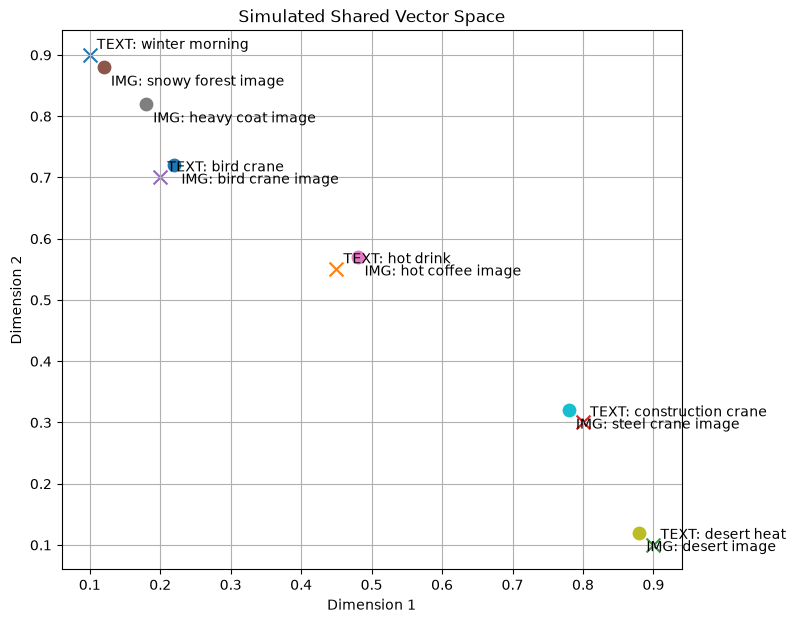

In [3]:
plt.figure(figsize=(8, 7))

for label, vector in text_embeddings.items():
    plt.scatter(vector[0], vector[1], marker="x", s=100)
    plt.text(vector[0] + 0.01, vector[1] + 0.01, "TEXT: " + label)

for label, vector in image_embeddings.items():
    plt.scatter(vector[0], vector[1], marker="o", s=80)
    plt.text(vector[0] + 0.01, vector[1] - 0.03, "IMG: " + label)

plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.title("Simulated Shared Vector Space")
plt.grid(True)
plt.show()

## Practice 1: Read the Shared Space

Look at the plot.

Answer:

1. Which images are closest to `"winter morning"`?
2. Which image is closest to `"desert heat"`?
3. Which image is closest to `"construction crane"`?
4. Why is the bird crane image far from the steel crane image?

In [4]:
# Practice 1 answers

# 1.
# 2.
# 3.
# 4.

# Part 5: Cosine Similarity for Text-to-Image Matching

To compare a text embedding and an image embedding, we can use cosine similarity.

Cosine similarity measures whether two vectors point in a similar direction.

Values:

```text
Close to 1  → very similar
Close to 0  → weakly related
Close to -1 → opposite direction
```

In [5]:
def cosine_similarity(a, b):
    dot_product = np.dot(a, b)
    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)
    return dot_product / (norm_a * norm_b)

query = text_embeddings["winter morning"]

scores = []

for image_name, image_vector in image_embeddings.items():
    score = cosine_similarity(query, image_vector)
    scores.append((score, image_name))

scores = sorted(scores, reverse=True)

print("Query: winter morning")
print("\nRanked image results:")
for score, image_name in scores:
    print(f"{score:.4f} → {image_name}")

Query: winter morning

Ranked image results:
0.9997 → snowy forest image
0.9944 → heavy coat image
0.9828 → bird crane image
0.8314 → hot coffee image
0.4794 → steel crane image
0.2437 → desert image


# Part 6: Ranking Images by Semantic Distance

In class, your instructor may show four images:

A. Snowy forest  
B. Hot cup of coffee  
C. Person in a heavy coat  
D. Desert landscape  

Query:

```text
Winter Morning
```

A multimodal model should rank images based on semantic closeness.

The model might rank:

```text
1. Snowy forest
2. Person in heavy coat
3. Hot cup of coffee
4. Desert landscape
```

Why?

Because snowy forest and heavy coat both point toward the cold/winter part of the vector space.

In [6]:
winter_query = text_embeddings["winter morning"]

candidate_images = {
    "A - snowy forest": image_embeddings["snowy forest image"],
    "B - hot coffee": image_embeddings["hot coffee image"],
    "C - heavy coat": image_embeddings["heavy coat image"],
    "D - desert landscape": image_embeddings["desert image"]
}

ranked = []

for image_name, vector in candidate_images.items():
    score = cosine_similarity(winter_query, vector)
    ranked.append((score, image_name))

ranked = sorted(ranked, reverse=True)

for rank, (score, image_name) in enumerate(ranked, start=1):
    print(f"{rank}. {image_name} | similarity: {score:.4f}")

1. A - snowy forest | similarity: 0.9997
2. C - heavy coat | similarity: 0.9944
3. B - hot coffee | similarity: 0.8314
4. D - desert landscape | similarity: 0.2437


## Practice 2: Try a Different Query

Use the query `"desert heat"`.

Rank the same four images again.

Which image comes first?

In [7]:
# Practice 2

desert_query = text_embeddings["desert heat"]

ranked = []

for image_name, vector in candidate_images.items():
    score = cosine_similarity(desert_query, vector)
    ranked.append((score, image_name))

ranked = sorted(ranked, reverse=True)

for rank, (score, image_name) in enumerate(ranked, start=1):
    print(f"{rank}. {image_name} | similarity: {score:.4f}")

1. D - desert landscape | similarity: 0.9997
2. B - hot coffee | similarity: 0.7247
3. C - heavy coat | similarity: 0.3210
4. A - snowy forest | similarity: 0.2437


# Part 7: Ambiguity and Context

Some words have multiple meanings.

Example:

```text
Crane
```

A crane could be:

1. A bird
2. A construction machine

Text alone may be ambiguous.

Images help resolve meaning.

If the image has feathers and water, the meaning is probably bird.

If the image has steel and a hook, the meaning is probably construction machine.

In [8]:
crane_query_bird = text_embeddings["bird crane"]
crane_query_machine = text_embeddings["construction crane"]

crane_images = {
    "steel crane image": image_embeddings["steel crane image"],
    "bird crane image": image_embeddings["bird crane image"]
}

print("Query: bird crane")
for image_name, vector in crane_images.items():
    score = cosine_similarity(crane_query_bird, vector)
    print(f"{score:.4f} → {image_name}")

print("\nQuery: construction crane")
for image_name, vector in crane_images.items():
    score = cosine_similarity(crane_query_machine, vector)
    print(f"{score:.4f} → {image_name}")

Query: bird crane
0.6191 → steel crane image
0.9998 → bird crane image

Query: construction crane
0.9995 → steel crane image
0.6094 → bird crane image


## Practice 3: Ambiguous Words

Think of three ambiguous words.

Examples:

- bark
- bat
- seal
- mouse
- spring
- apple

For each word, write two different meanings and describe what image context would clarify the meaning.

In [9]:
# Practice 3

ambiguous_words = {
    "bark": ["tree bark", "dog barking"],
    "bat": ["baseball bat", "flying animal"],
    "seal": ["marine animal", "stamp/seal"]
}

for word, meanings in ambiguous_words.items():
    print(word, "→", meanings)

bark → ['tree bark', 'dog barking']
bat → ['baseball bat', 'flying animal']
seal → ['marine animal', 'stamp/seal']


# Part 8: Simulated Multimodal Search Function

Now we will create a simple function that takes a text query vector and returns the closest images.

This simulates text-to-image retrieval.

In [10]:
def search_images_by_text(query_vector, image_vectors, n_results=3):
    results = []

    for image_name, image_vector in image_vectors.items():
        score = cosine_similarity(query_vector, image_vector)
        results.append((score, image_name))

    results = sorted(results, reverse=True)
    return results[:n_results]

results = search_images_by_text(text_embeddings["winter morning"], image_embeddings, n_results=3)

for score, image_name in results:
    print(f"{score:.4f} → {image_name}")

0.9997 → snowy forest image
0.9944 → heavy coat image
0.9828 → bird crane image


# Part 9: Final Project Digital Pipeline

For the final project, your multimodal search assistant will follow a pipeline like this:

```text
Text Prompt
        ↓
OpenAI API / Embedding Model
        ↓
Query Vector
        ↓
Vector Database
        ↓
Nearest Image Embeddings
        ↓
Image URIs
        ↓
Retrieved Images
```

This is not just keyword matching.

It is meaning-based search across different media types.

## Practice 4: Design Your Pipeline

Choose a niche for your final project.

Examples:

- Architecture
- Marine Life
- Culinary Arts
- Fashion
- Travel Photography
- Outdoor Gear
- Product Search

Then fill in the pipeline for your niche.

In [11]:
# Practice 4

niche = "Outdoor Gear"

pipeline = {
    "text_prompt": "waterproof jacket for mountain hiking",
    "embedding_model": "OpenAI embedding model or CLIP-style model",
    "vector_database": "ChromaDB",
    "retrieval_target": "image URIs of matching gear",
    "expected_results": [
        "rain jacket image",
        "windbreaker image",
        "waterproof hiking shell image"
    ]
}

for step, value in pipeline.items():
    print(step, "→", value)

text_prompt → waterproof jacket for mountain hiking
embedding_model → OpenAI embedding model or CLIP-style model
vector_database → ChromaDB
retrieval_target → image URIs of matching gear
expected_results → ['rain jacket image', 'windbreaker image', 'waterproof hiking shell image']


# Part 10: Semantic Database Mapping Activity

Goal:

Design a multimodal dataset logic that uses shared vector space to resolve ambiguity before implementation.

Tasks:

1. Define a niche.
2. Curate ambiguous pairs.
3. Map the digital pipeline.
4. Predict semantic distance.

In [12]:
# Semantic Database Mapping Template

niche = "Culinary Arts"

ambiguous_pairs = [
    {
        "word": "batter",
        "meaning_1": "cake batter in a mixing bowl",
        "meaning_2": "baseball batter holding a bat",
        "visual_context_1": "bowl, flour, spoon, kitchen",
        "visual_context_2": "baseball field, helmet, bat"
    },
    {
        "word": "jam",
        "meaning_1": "fruit jam in a jar",
        "meaning_2": "traffic jam",
        "visual_context_1": "jar, toast, fruit",
        "visual_context_2": "cars, road, congestion"
    },
    {
        "word": "crane",
        "meaning_1": "bird near water",
        "meaning_2": "construction machine",
        "visual_context_1": "feathers, water, long legs",
        "visual_context_2": "steel, hook, construction site"
    }
]

for pair in ambiguous_pairs:
    print("\nWord:", pair["word"])
    print("Meaning 1:", pair["meaning_1"])
    print("Visual context 1:", pair["visual_context_1"])
    print("Meaning 2:", pair["meaning_2"])
    print("Visual context 2:", pair["visual_context_2"])


Word: batter
Meaning 1: cake batter in a mixing bowl
Visual context 1: bowl, flour, spoon, kitchen
Meaning 2: baseball batter holding a bat
Visual context 2: baseball field, helmet, bat

Word: jam
Meaning 1: fruit jam in a jar
Visual context 1: jar, toast, fruit
Meaning 2: traffic jam
Visual context 2: cars, road, congestion

Word: crane
Meaning 1: bird near water
Visual context 1: feathers, water, long legs
Meaning 2: construction machine
Visual context 2: steel, hook, construction site


# Part 11: Vector Database Item Structure

In a multimodal search app, each image item may have:

- ID
- Text description
- Category
- URI or file path
- Embedding

Example:

```python
{
    "id": "image1",
    "description": "snowy forest trail",
    "uri": "./images/snowy_forest.jpg",
    "category": "winter"
}
```

The vector database stores searchable meaning and metadata.

The URI tells your app where to find the original image.

In [13]:
image_items = [
    {
        "id": "img1",
        "description": "snowy forest trail during winter morning",
        "uri": "./images/snowy_forest.jpg",
        "category": "winter"
    },
    {
        "id": "img2",
        "description": "hot cup of coffee on a wooden table",
        "uri": "./images/coffee.jpg",
        "category": "morning"
    },
    {
        "id": "img3",
        "description": "person wearing a heavy coat in cold weather",
        "uri": "./images/heavy_coat.jpg",
        "category": "winter"
    },
    {
        "id": "img4",
        "description": "desert landscape under bright sun",
        "uri": "./images/desert.jpg",
        "category": "desert"
    }
]

for item in image_items:
    print(item)

{'id': 'img1', 'description': 'snowy forest trail during winter morning', 'uri': './images/snowy_forest.jpg', 'category': 'winter'}
{'id': 'img2', 'description': 'hot cup of coffee on a wooden table', 'uri': './images/coffee.jpg', 'category': 'morning'}
{'id': 'img3', 'description': 'person wearing a heavy coat in cold weather', 'uri': './images/heavy_coat.jpg', 'category': 'winter'}
{'id': 'img4', 'description': 'desert landscape under bright sun', 'uri': './images/desert.jpg', 'category': 'desert'}


# Part 12: OpenAI API Concept

An API lets your app communicate with an AI model.

Analogy:

| Concept | Analogy |
|---|---|
| Streamlit app | Customer |
| API | Waiter |
| AI model | Chef |
| Response | Food returned to the customer |

Your app sends a request to the API.

The model processes it.

The API returns the response.

# Part 13: Secure API Key Storage

An API key is a sensitive credential.

Treat it like:

```text
password
credit card
private key
```

Do not hardcode it into a Python file.

Do not upload it to GitHub.

For Streamlit, use this structure:

```text
project_folder/
    app.py
    .streamlit/
        secrets.toml
```

Inside `secrets.toml`:

```toml
OPENAI_API_KEY = "your_key_here"
```

Inside Streamlit:

```python
import streamlit as st

api_key = st.secrets["OPENAI_API_KEY"]
```

In [14]:
# This cell does NOT use a real API key.
# It demonstrates how to safely mask a key.

fake_api_key = "sk-demo1234567890abcdef"

masked_key = fake_api_key[:4] + "..." + fake_api_key[-4:]

print("Masked key:", masked_key)
print("Never print the full key.")

Masked key: sk-d...cdef
Never print the full key.


# Part 14: Streamlit Secret Verification Script

In a real Streamlit app, you can verify that the key loads correctly without exposing it.

Example:

```python
import streamlit as st

api_key = st.secrets["OPENAI_API_KEY"]

masked_key = api_key[:4] + "..." + api_key[-4:]

st.success(f"API key loaded: {masked_key}")
```

This confirms the setup without leaking the full key.

In [15]:
streamlit_secret_check_script = '''
import streamlit as st

st.title("API Key Check")

api_key = st.secrets["OPENAI_API_KEY"]

masked_key = api_key[:4] + "..." + api_key[-4:]

st.success(f"API key loaded: {masked_key}")
'''

print(streamlit_secret_check_script)


import streamlit as st

st.title("API Key Check")

api_key = st.secrets["OPENAI_API_KEY"]

masked_key = api_key[:4] + "..." + api_key[-4:]

st.success(f"API key loaded: {masked_key}")



# Part 15: Token Counting with tiktoken

API cost is often based on token usage.

Before sending large amounts of text, count tokens.

Install tiktoken:

```bash
pip install tiktoken
```

If `tiktoken` is not installed in this notebook environment, the cell will show an installation message instead of crashing.

In [16]:
descriptions = [
    "A snowy forest trail during a quiet winter morning.",
    "A hot cup of coffee on a wooden table near a window.",
    "A person wearing a heavy coat while walking in cold weather.",
    "A desert landscape under bright sunlight with sand dunes."
]

try:
    import tiktoken

    encoding = tiktoken.get_encoding("cl100k_base")

    total_tokens = 0

    for description in descriptions:
        tokens = encoding.encode(description)
        token_count = len(tokens)
        total_tokens += token_count

        print(description)
        print("Token count:", token_count)
        print("Token IDs:", tokens)
        print()

    print("Total tokens:", total_tokens)

except ImportError:
    print("tiktoken is not installed.")
    print("Install it with: pip install tiktoken")

    # Approximate fallback using word count rule of thumb
    total_words = sum(len(description.split()) for description in descriptions)
    estimated_tokens = int(total_words * (1000 / 750))
    print("Estimated tokens using rule of thumb:", estimated_tokens)

tiktoken is not installed.
Install it with: pip install tiktoken
Estimated tokens using rule of thumb: 54


# Part 16: Cost Calculation

Example pricing assumption for this course:

```text
text-embedding-3-small = $0.02 per 1 million tokens
```

Always verify current pricing before a real deployment.

Formula:

```text
cost = (total_tokens / 1,000,000) × price_per_million_tokens
```

In [17]:
def calculate_embedding_cost(total_tokens, price_per_million=0.02):
    cost = (total_tokens / 1_000_000) * price_per_million
    return cost

example_total_tokens = 5000
price_per_million = 0.02

cost = calculate_embedding_cost(example_total_tokens, price_per_million)

print("Total tokens:", example_total_tokens)
print("Price per 1M tokens:", price_per_million)
print("Estimated cost: $", cost)

Total tokens: 5000
Price per 1M tokens: 0.02
Estimated cost: $ 0.0001


## Practice 5: Cost Audit

Use your own image descriptions from your final project plan.

Tasks:

1. Write 5 descriptions.
2. Count or estimate total tokens.
3. Calculate embedding cost.
4. Explain whether the cost is reasonable for your project.

In [18]:
# Practice 5

my_descriptions = [
    "A waterproof hiking jacket on a mountain trail.",
    "A breathable windbreaker for cool spring weather.",
    "A heavy winter parka designed for snowstorms.",
    "Trail running shoes with strong grip and support.",
    "A compact camping lantern glowing inside a tent."
]

# Approximate fallback using word count rule of thumb
total_words = sum(len(description.split()) for description in my_descriptions)
estimated_tokens = int(total_words * (1000 / 750))

estimated_cost = calculate_embedding_cost(estimated_tokens, price_per_million=0.02)

print("Total words:", total_words)
print("Estimated tokens:", estimated_tokens)
print("Estimated embedding cost: $", estimated_cost)

Total words: 38
Estimated tokens: 50
Estimated embedding cost: $ 1.0000000000000002e-06


# Part 17: Optional OpenAI Client Structure

This notebook does not require a real API call.

However, the structure of an OpenAI API client usually looks like this:

```python
from openai import OpenAI
import streamlit as st

client = OpenAI(api_key=st.secrets["OPENAI_API_KEY"])

response = client.embeddings.create(
    model="text-embedding-3-small",
    input="A snowy forest trail during winter."
)

embedding = response.data[0].embedding
```

In a real app, you would send descriptions or queries to the embedding model and store the resulting vectors in your vector database.

In [19]:
openai_embedding_example = '''
from openai import OpenAI
import streamlit as st

client = OpenAI(api_key=st.secrets["OPENAI_API_KEY"])

response = client.embeddings.create(
    model="text-embedding-3-small",
    input="A snowy forest trail during winter."
)

embedding = response.data[0].embedding

print(len(embedding))
'''

print(openai_embedding_example)


from openai import OpenAI
import streamlit as st

client = OpenAI(api_key=st.secrets["OPENAI_API_KEY"])

response = client.embeddings.create(
    model="text-embedding-3-small",
    input="A snowy forest trail during winter."
)

embedding = response.data[0].embedding

print(len(embedding))



# Part 18: Final Project Planning Worksheet

Use this section to outline your Lesson 13 project.

Your project should use:

```text
Text Prompt → Embedding → Vector Database → Image Retrieval
```

In [20]:
# Final Project Planning Worksheet

project_plan = {
    "niche": "Outdoor Gear",
    "user_query_example": "waterproof jacket for hiking in cold weather",
    "data_items": [
        {
            "id": "item1",
            "description": "Lightweight raincoat for wet mountain trails",
            "uri": "./images/raincoat.jpg"
        },
        {
            "id": "item2",
            "description": "Insulated winter parka for snow and wind",
            "uri": "./images/parka.jpg"
        },
        {
            "id": "item3",
            "description": "Breathable windbreaker for spring hikes",
            "uri": "./images/windbreaker.jpg"
        }
    ],
    "retrieval_goal": "Return the most semantically relevant product images for the user's text query."
}

for key, value in project_plan.items():
    print(key, ":", value)

niche : Outdoor Gear
user_query_example : waterproof jacket for hiking in cold weather
data_items : [{'id': 'item1', 'description': 'Lightweight raincoat for wet mountain trails', 'uri': './images/raincoat.jpg'}, {'id': 'item2', 'description': 'Insulated winter parka for snow and wind', 'uri': './images/parka.jpg'}, {'id': 'item3', 'description': 'Breathable windbreaker for spring hikes', 'uri': './images/windbreaker.jpg'}]
retrieval_goal : Return the most semantically relevant product images for the user's text query.


# Part 19: Independent Work Summary

## Activity 1: Semantic Database Mapping

Goal:

Design multimodal dataset logic that uses CLIP-style vector space to resolve search ambiguity.

Tasks:

1. Define a niche.
2. Identify three ambiguous image/text pairs.
3. Diagram the pipeline.
4. Predict semantic distance for each pair.

---

## Activity 2: API Security and Usage Audit

Goal:

Create a secure API environment and calculate token usage.

Tasks:

1. Create `.streamlit/secrets.toml`.
2. Store your OpenAI API key safely.
3. Write a masked key verification script.
4. Use `tiktoken` to count description tokens.
5. Calculate estimated embedding cost.

# Final Reflection

Answer these questions:

1. What is multimodal AI?
2. What does CLIP do?
3. What is a shared vector space?
4. Why can text and images be compared in CLIP-style systems?
5. How does visual context help resolve ambiguity?
6. What is semantic distance?
7. What is the role of a vector database in multimodal search?
8. Why should API keys never be hardcoded?
9. Why should keys be masked when verifying setup?
10. Why is token counting useful?
11. How does this lesson prepare you for the final project?

In [21]:
# Final Reflection Answers

# 1.
# 2.
# 3.
# 4.
# 5.
# 6.
# 7.
# 8.
# 9.
# 10.
# 11.